# Indicators

**Goal.** Plot standard price overlays on NVDA. This notebook does not test a forecast.

**Method.** Daily bars from the start of 2024. Moving averages, Keltner channels, the range filter, and MACD are computed in `src/indicators.py`.

**Result.** Two charts. No rule is evaluated and no performance number comes from this notebook.


In [ ]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


[*********************100%***********************]  1 of 1 completed


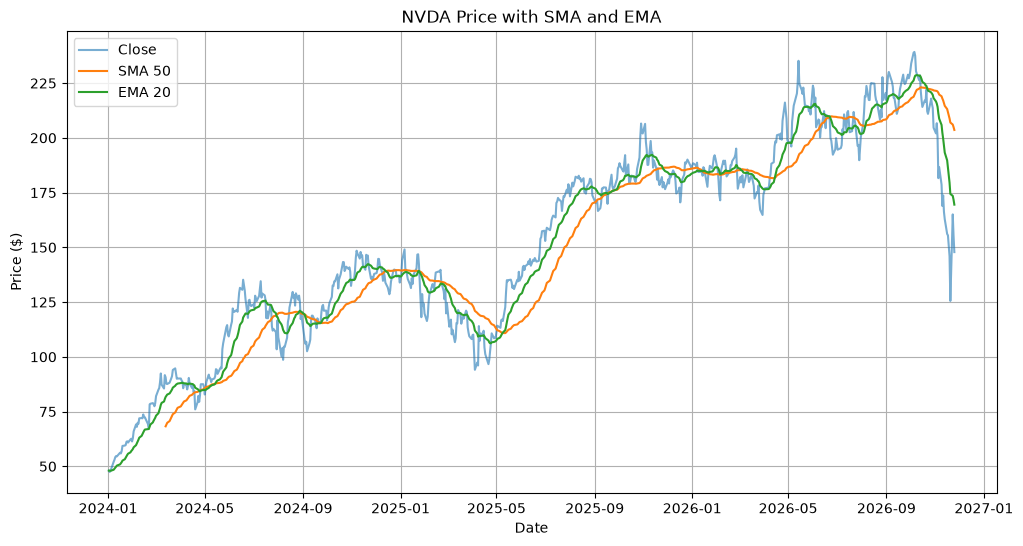

In [1]:
import yfinance as yf
import matplotlib.pyplot as plt

from src.indicators import sma, ema

ticker = "NVDA"
df = yf.download(ticker, start="2024-01-01", multi_level_index=False)
df["SMA_50"] = sma(df["Close"], 50)
df["EMA_20"] = ema(df["Close"], 20)

plt.figure(figsize=(12, 6))
plt.plot(df.index, df["Close"], label="Close", alpha=0.6)
plt.plot(df.index, df["SMA_50"], label="SMA 50")
plt.plot(df.index, df["EMA_20"], label="EMA 20")
plt.title(f"{ticker} Price with SMA and EMA")
plt.xlabel("Date")
plt.ylabel("Price ($)")
plt.legend()
plt.grid(True)
plt.show()


[*********************100%***********************]  1 of 1 completed


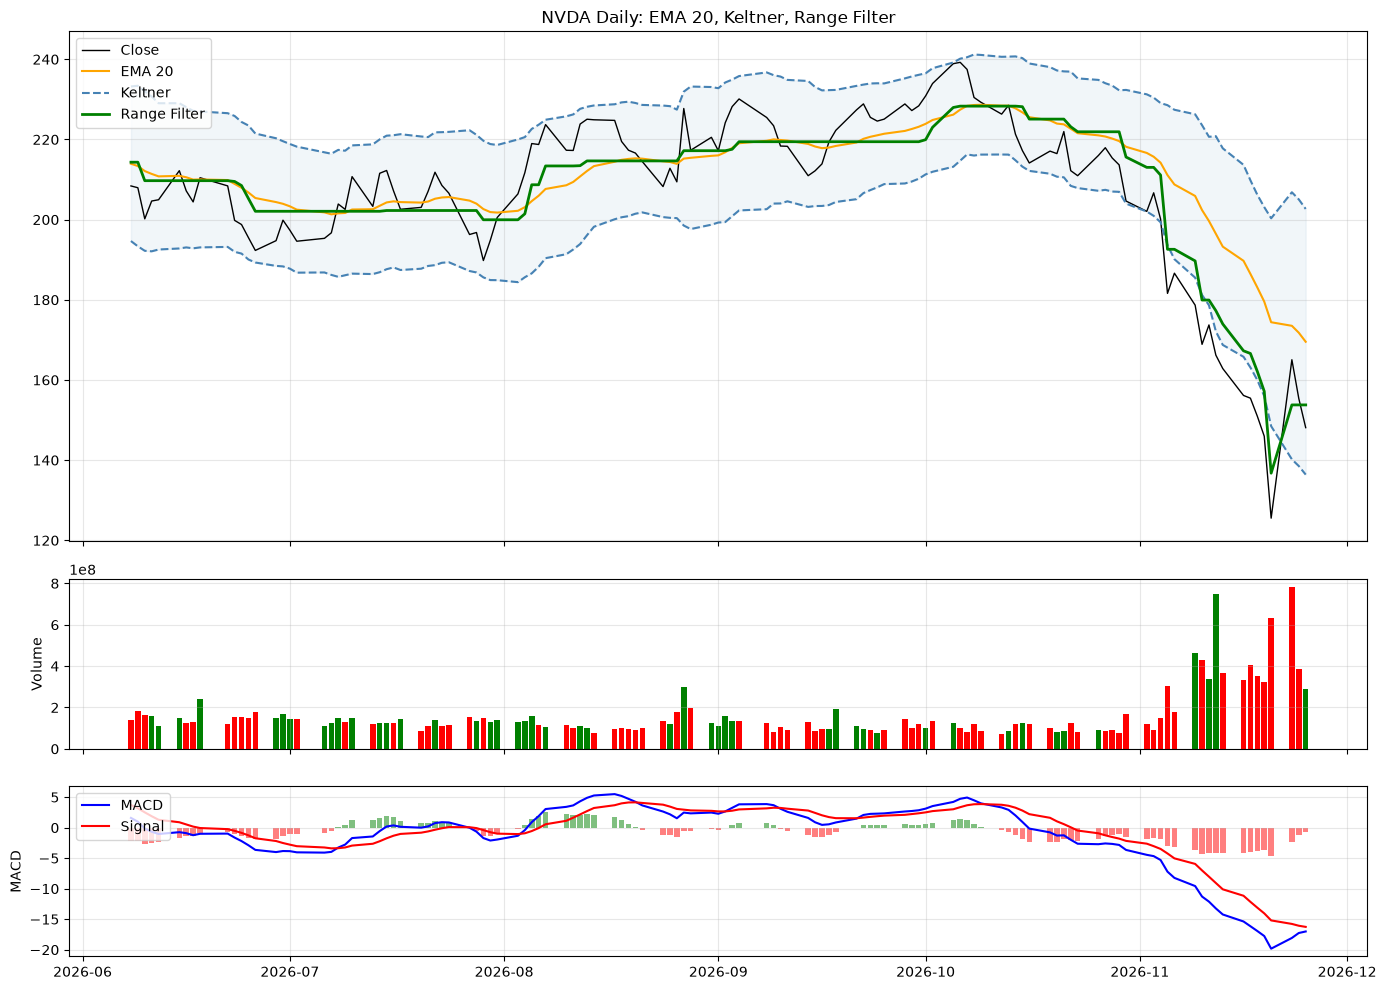

In [3]:
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt

from src.indicators import keltner, range_filter, macd

ticker = "NVDA"
df = yf.download(ticker, start="2024-01-01", interval="1d", multi_level_index=False).dropna()
df = keltner(df)
df["RangeFilter"] = range_filter(df["Close"])
df = df.join(macd(df["Close"]))

p = df.tail(120)
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 10), sharex=True,
                                    gridspec_kw={"height_ratios": [3, 1, 1]})
ax1.plot(p.index, p["Close"], label="Close", color="black", linewidth=1)
ax1.plot(p.index, p["EMA20"], label="EMA 20", color="orange")
ax1.plot(p.index, p["KC_upper"], label="Keltner", color="steelblue", linestyle="--")
ax1.plot(p.index, p["KC_lower"], color="steelblue", linestyle="--")
ax1.fill_between(p.index, p["KC_lower"], p["KC_upper"], color="steelblue", alpha=0.07)
ax1.plot(p.index, p["RangeFilter"], label="Range Filter", color="green", linewidth=2)
ax1.set_title(f"{ticker} Daily: EMA 20, Keltner, Range Filter")
ax1.legend(loc="upper left")
ax1.grid(True, alpha=0.3)

colors = np.where(p["Close"] >= p["Open"], "green", "red")
ax2.bar(p.index, p["Volume"], width=0.8, color=colors)
ax2.set_ylabel("Volume")
ax2.grid(True, alpha=0.3)

ax3.plot(p.index, p["MACD"], label="MACD", color="blue")
ax3.plot(p.index, p["Signal"], label="Signal", color="red")
ax3.bar(p.index, p["Hist"], width=0.8, color=np.where(p["Hist"] >= 0, "green", "red"), alpha=0.5)
ax3.set_ylabel("MACD")
ax3.legend(loc="upper left")
ax3.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
